In [23]:
# ==============================================================================
# 0. IMPORTAÇÃO DE BIBLIOTECAS E CONFIGURAÇÕES
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
# Configuração estética dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

In [46]:
from pathlib import Path

# ==============================================================================
# 1. CARREGAMENTO E DIAGNÓSTICO INICIAL DE QUALIDADE
# ==============================================================================
# Carregamento com separador correto ';' e limite de 10.000 linhas de dados
arquivo = "MATRIZ_CR_TIPO_PESSOA_2025.csv"
candidatos = [Path("dados") / arquivo, Path("../dados") / arquivo]
caminho_csv = next((p for p in candidatos if p.is_file()), None)

if caminho_csv is None:
    raise FileNotFoundError(
        f"Não foi encontrado {arquivo}. Diretório atual: {Path.cwd()}"
    )

df_raw = pd.read_csv(caminho_csv, sep=";", nrows=10000)

print(f"Dimensões do dataset original: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
print(f"Uso de memória: {df_raw.memory_usage().sum() / 1024**2:.2f} MB\n")

# Verificação de missing values e duplicados
print("Contagem de Faltantes por Coluna:")
print(df_raw.isnull().sum())
print(f"\nLinhas duplicadas identificadas: {df_raw.duplicated().sum()}")

Dimensões do dataset original: 10000 linhas x 28 colunas
Uso de memória: 2.14 MB

Contagem de Faltantes por Coluna:
ANO_MES_EMISSAO           0
TIPO_PESSOA               0
BENEFICIARIO              0
TIPO_BENEFICIARIO         0
GENERO                    0
FAIXA_IDADE               0
REGIAO                    0
UF                        0
ATIVIDADE                 0
PROGRAMA                  0
SUBPROGRAMA               0
FONTE_RECURSO             0
SEGMENTO_IF               0
CNPJ_IF                   0
NOME_IF                   0
CUSTEIO_AREA              0
CUSTEIO_QTDE              0
CUSTEIO_VALOR             0
INVESTIMENTO_AREA         0
INVESTIMENTO_QTDE         0
INVESTIMENTO_VALOR        0
COMERCIALIZACAO_QTDE      0
COMERCIALIZACAO_VALOR     0
INDUSTRIALIZACAO_QTDE     0
INDUSTRIALIZACAO_VALOR    0
TOTAL_AREA                0
TOTAL_QTDE                0
TOTAL_VALOR               0
dtype: int64

Linhas duplicadas identificadas: 0


In [34]:
# ==============================================================================
# 2. LIMPEZA, TRATAMENTO E TRANSFORMACÃO DE DADOS
# ==============================================================================
df = df_raw.copy()

# Justificativa de Engenharia:
# Os dados numéricos foram exportados em formato texto padrão brasileiro ("1639048,85").
# É necessário sanitizar os separadores de milhar e decimal para conversão em float64.

colunas_valor = [
    'CUSTEIO_AREA', 'CUSTEIO_VALOR', 
    'INVESTIMENTO_AREA', 'INVESTIMENTO_VALOR', 
    'COMERCIALIZACAO_VALOR', 'INDUSTRIALIZACAO_VALOR', 
    'TOTAL_AREA', 'TOTAL_VALOR'
]

for col in colunas_valor:
    df[col] = (df[col].astype(str)
               .str.replace('.', '', regex=False)
               .str.replace(',', '.', regex=False)
               .astype(float))

# Tratamento da variável de data
df['ANO_MES_EMISSAO'] = pd.to_datetime(df['ANO_MES_EMISSAO'])

# Mapeamento e padronização categórica via .map()
mapa_genero = {
    'MASCULINO': 'Masculino',
    'FEMININO': 'Feminino',
    'NÃO SE APLICA': 'Pessoa Jurídica / Não Informado'
}
df['GENERO_PADRONIZADO'] = df['GENERO'].map(mapa_genero).fillna('Outros')

In [35]:
# ==============================================================================
# 3. ENGENHARIA DE ATRIBUTOS (3 COLUNAS DERIVADAS)
# ==============================================================================
# Coluna 1: Ticket Médio por Operação (Uso de np.where para evitar divisão por zero)
df['VALOR_MEDIO_OPERACAO'] = np.where(
    df['TOTAL_QTDE'] > 0, 
    df['TOTAL_VALOR'] / df['TOTAL_QTDE'], 
    0.0
)

# Coluna 2: Densidade Financeira por Hectare (R$/ha)
df['VALOR_POR_HECTARE'] = np.where(
    df['TOTAL_AREA'] > 0, 
    df['TOTAL_VALOR'] / df['TOTAL_AREA'], 
    np.nan
)

# Coluna 3: Classificação do Porte Financeiro por Quantil via pd.qcut
df['FAIXA_PORTE_CONTRATO'] = pd.qcut(
    df['TOTAL_VALOR'], 
    q=4, 
    labels=['Pequeno Porte', 'Médio Porte', 'Grande Porte', 'Mega Operação']
)

In [37]:
# ==============================================================================
# 4. TRATAMENTO DE OUTLIERS COM NUMPY (Z-SCORE POR GRUPO REGIONAL)
# ==============================================================================
# Justificativa:
# Outliers em crédito rural não devem ser avaliados no agregador nacional,
# pois a escala do Centro-Oeste difere drasticamente do Nordeste/Norte.

media_regional = df.groupby('REGIAO')['TOTAL_VALOR'].transform('mean')
std_regional = df.groupby('REGIAO')['TOTAL_VALOR'].transform('std')

# Fórmula do Z-Score vetorizado em NumPy: Z = |X - mu| / sigma
df['Z_SCORE_REGIONAL'] = np.abs((df['TOTAL_VALOR'] - media_regional) / std_regional)

outliers_detectados = df[df['Z_SCORE_REGIONAL'] > 3]
print(f"Total de operações atípicas (Z-score > 3 por Região): {len(outliers_detectados)} registros")



Total de operações atípicas (Z-score > 3 por Região): 68 registros


In [38]:
# ==============================================================================
# 5. JUNÇÃO COM TABELA AUXILIAR (MERGE)
# ==============================================================================
# Tabela de domínio auxiliar com perfil regional agropecuário
df_regioes_aux = pd.DataFrame({
    'REGIAO': ['SUL', 'CENTRO-OESTE', 'SUDESTE', 'NORDESTE', 'NORTE'],
    'PERFIL_LOGISTICO': ['Alta Malha / Cooperativismo', 'Escoamento Grãos / Modal Ferroviário', 
                         'Proximidade Portuária / Agroindústria', 'Vulnerabilidade Hídrica', 'Fronteira Agrícola / Extensivo'],
    'INDICE_COOPERATIVIZACAO': [0.85, 0.45, 0.60, 0.25, 0.20]
})

linhas_antes_merge = len(df)
df_analise = df.merge(df_regioes_aux, on='REGIAO', how='left')
assert len(df_analise) == linhas_antes_merge, "Erro de cardinalidade: número de linhas alterado pós-merge!"

In [39]:
# ==============================================================================
# 6. AGREGAÇÕES AVANÇADAS (GROUPBY & PIVOT_TABLE)
# ==============================================================================
# Groupby Múltiplo
agregacao_regional = df_analise.groupby(['REGIAO', 'GENERO_PADRONIZADO']).agg(
    QTD_CONTRATOS=('TOTAL_QTDE', 'sum'),
    VALOR_TOTAL_R=('TOTAL_VALOR', 'sum'),
    VALOR_MEDIO_R=('TOTAL_VALOR', 'mean'),
    VALOR_MEDIANO_R=('TOTAL_VALOR', 'median')
).reset_index()

# Pivot Table: Programa de Crédito vs. Região geográfica
pivot_programas = pd.pivot_table(
    df_analise,
    values='TOTAL_VALOR',
    index='BENEFICIARIO',
    columns='REGIAO',
    aggfunc='sum',
    fill_value=0
) / 1e6  # Convertido para Milhões de R$

print("\n--- Tabela Dinâmica: Volume por Beneficiário vs. Região (R$ Mi) ---")
print(pivot_programas.round(2))


--- Tabela Dinâmica: Volume por Beneficiário vs. Região (R$ Mi) ---
REGIAO                                CENTRO-OESTE  NORDESTE   NORTE  SUDESTE  \
BENEFICIARIO                                                                    
COOPERATIVA DE PRODUÇÃO AGROPECUÁRIA       1163.44    420.07   32.67   874.47   
DEMAIS PESSOAS FÍSICAS                     2450.35    644.47  611.04  1247.13   
DEMAIS PESSOAS JURÍDICAS                    264.98      0.40    7.89   649.70   
VINCULADO AO PRONAF                         143.76    511.28  251.95   432.19   
VINCULADO AO PRONAMP                        276.55    107.23  115.64   693.51   

REGIAO                                    SUL  
BENEFICIARIO                                   
COOPERATIVA DE PRODUÇÃO AGROPECUÁRIA   399.88  
DEMAIS PESSOAS FÍSICAS                 925.09  
DEMAIS PESSOAS JURÍDICAS              1095.62  
VINCULADO AO PRONAF                   1105.45  
VINCULADO AO PRONAMP                   886.09  


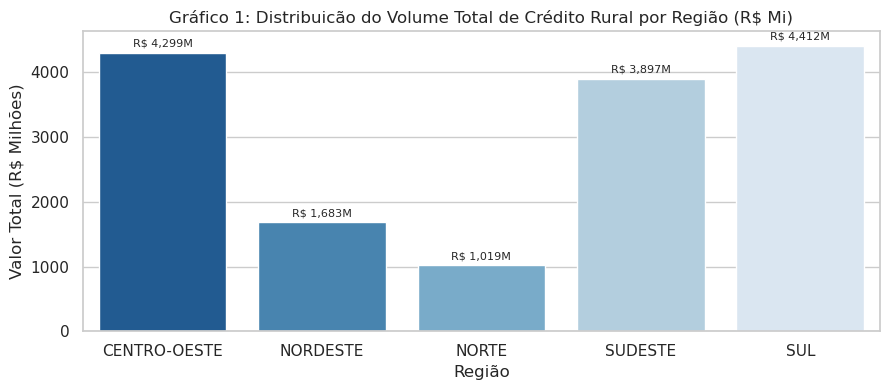

In [40]:
# ==============================================================================
# GERADOR DOS 4 GRÁFICOS OBRIGATÓRIOS
# ==============================================================================

# Gráfico 1: Volume de Crédito por Região
plt.figure(figsize=(9, 4))
df_reg_sum = df_analise.groupby('REGIAO')['TOTAL_VALOR'].sum() / 1e6
ax1 = sns.barplot(x=df_reg_sum.index, y=df_reg_sum.values, palette='Blues_r')
plt.title('Gráfico 1: Distribuicão do Volume Total de Crédito Rural por Região (R$ Mi)')
plt.ylabel('Valor Total (R$ Milhões)')
plt.xlabel('Região')
for p in ax1.patches:
    ax1.annotate(f'R$ {p.get_height():,.0f}M', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()
# Leitura em Texto:
# O Sul e o Centro-Oeste lideram a captação financeira, somando R$ 8,71 bilhões dos R$ 15,31 bilhões analisados.
# Isso reflete o alto grau de mecanização e a escala das safras de grãos nessas regiões.

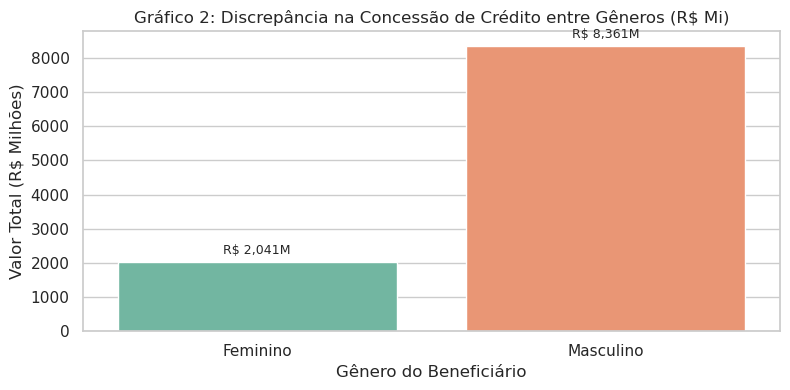

In [41]:
# Gráfico 2: Desigualdade de Gênero na Captação
plt.figure(figsize=(8, 4))
df_pf = df_analise[df_analise['GENERO_PADRONIZADO'].isin(['Masculino', 'Feminino'])]
df_genero_sum = df_pf.groupby('GENERO_PADRONIZADO')['TOTAL_VALOR'].sum() / 1e6
ax2 = sns.barplot(x=df_genero_sum.index, y=df_genero_sum.values, palette='Set2')
plt.title('Gráfico 2: Discrepância na Concessão de Crédito entre Gêneros (R$ Mi)')
plt.ylabel('Valor Total (R$ Milhões)')
plt.xlabel('Gênero do Beneficiário')
for p in ax2.patches:
    ax2.annotate(f'R$ {p.get_height():,.0f}M', (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()
# Leitura em Texto:
# Produtores do gênero masculino concentram R$ 8,36 bilhões (80,4% do crédito concedido a pessoas físicas),
# enquanto mulheres acessaram R$ 2,04 bilhões (19,6%), evidenciando lacuna no acesso a capital de fomento.

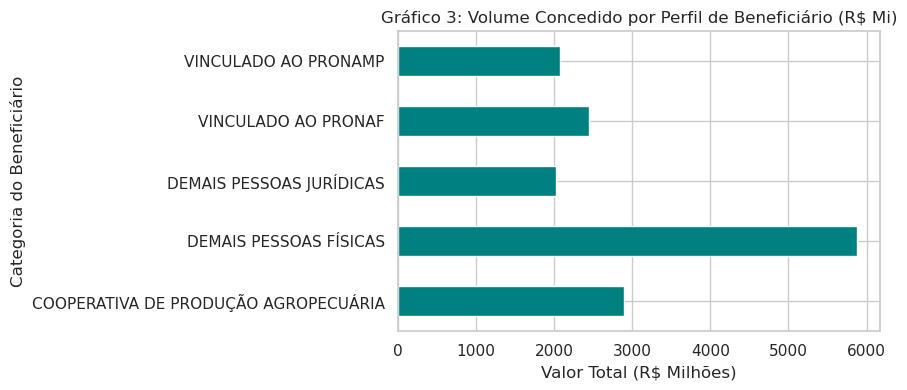

In [42]:
# Gráfico 3: Participação do PRONAF e PRONAMP vs Demais
plt.figure(figsize=(9, 4))
df_ben = df_analise.groupby('BENEFICIARIO')['TOTAL_VALOR'].sum() / 1e6
ax3 = df_ben.plot(kind='barh', color='teal')
plt.title('Gráfico 3: Volume Concedido por Perfil de Beneficiário (R$ Mi)')
plt.xlabel('Valor Total (R$ Milhões)')
plt.ylabel('Categoria do Beneficiário')
plt.tight_layout()
plt.show()
# Leitura em Texto:
# Os contratos vinculados ao PRONAF (R$ 2,44 Bi) e PRONAMP (R$ 2,08 Bi) garantem a pulverização do crédito 
# para pequenos e médios produtores, embora operações de Demais Pessoas Físicas absorvam a maior fatia individual.

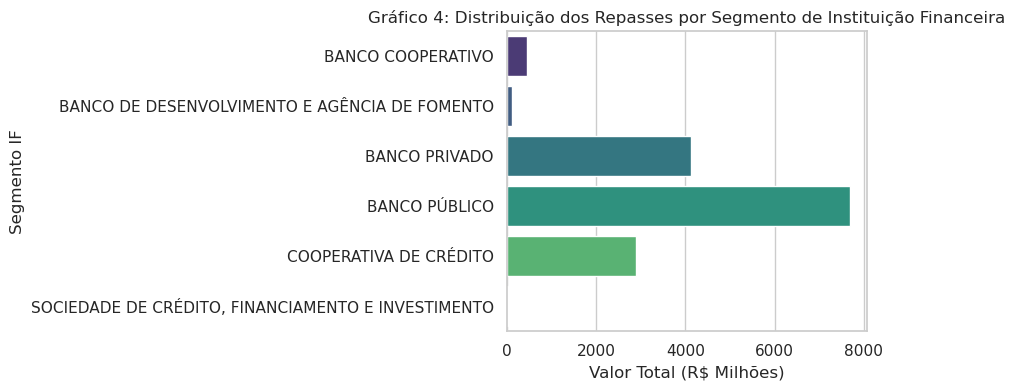

In [44]:
# Gráfico 4: Segmento de Instituição Financeira
plt.figure(figsize=(9, 4))
df_if = df_analise.groupby('SEGMENTO_IF')['TOTAL_VALOR'].sum() / 1e6
ax4 = sns.barplot(x=df_if.values, y=df_if.index, palette='viridis')
plt.title('Gráfico 4: Distribuição dos Repasses por Segmento de Instituição Financeira')
plt.xlabel('Valor Total (R$ Milhões)')
plt.ylabel('Segmento IF')
plt.tight_layout()
plt.show()
# Leitura em Texto:
# As Cooperativas de Crédito e os Bancos Públicos atuam como os principais agentes operadores da política
# agrícola nacional, superando a atuação direta de bancos privados comerciais nas regiões interioranas.